Under our banking setup, an agent $i$ observes their immediate social neighborhood and evaluates the local panic rate weighted by deposit volume ($v_i$). Knowing the exact size of a neighbor’s deposit ($w_i$) is, of course, a simplifying assumption. However, having a rough sense of a peer's financial standing is quite plausible in a close network. 

Under this framework, a patient depositor $i$ holding $w_i$ in deposits calculates their expected terminal payout at $t=2$, conditional on the local volume-weighted panic rate $v_i$, as:

$$E[V_{2,i}\vert{}v_i] = \frac{E[Y(\theta)]\left(I_0 - \frac{\max\{v_iD_0r - \alpha D_0,0\}}{\ell}\right) + \max\{\alpha D_0 - v_iD_0r,0\}}{(1-v_i)D_0}w_i$$

Comparing this against the guaranteed early redemption payout at $t=1$, $E[V_{1,i}\vert{}v_i] = rw_i$, the agent rationally chooses to wait as long as $E[V_{2,i}\vert{}v_i] > E[V_{1,i}\vert{}v_i]$:

$$\frac{E[Y(\theta)]\left(I_0 - \frac{\max\{v_iD_0r - \alpha D_0,0\}}{\ell}\right) + \max\{\alpha D_0 - v_iD_0r,0\}}{(1-v_i)D_0} > r$$

Dividing through by $D_0$ and expressing initial illiquid assets relative to total deposits as $i_0 = \frac{I_0}{D_0} = (1 - \alpha) + \frac{E_0}{D_0}$, we get a cleaner form:

$$\frac{E[Y(\theta)]\left(i_0 - \frac{\max\{v_ir - \alpha,0\}}{\ell}\right) + \max\{\alpha - v_ir,0\}}{(1-v_i)} > r$$

To check for analytical consistency, we can apply the standard Diamond–Dybvig benchmark conditions: zero liquid reserves ($\alpha = 0$), frictionless liquidation ($\ell = 1$), and a deterministic investment yield equal to the contractual return ($E[Y(\theta)] = R$). Under these constraints, the rule simplifies to:

$$\frac{R\left(i_0 - v_ir\right)}{1-v_i} > r$$

Finally, if we assume uniform deposit sizes ($w_i = 1$), zero initial equity ($E_0 = 0 \implies i_0 = 1$), and a fully connected network where local observation equals global observation ($v_i = \lambda$), the condition reduces directly to:

$$\frac{R\left(1 - \lambda r\right)}{1-\lambda} > r$$

This recovers the classic Diamond–Dybvig (1983) payoff schedule and no-run condition. It confirms that our proposed decision rule is a well-behaved generalization that naturally incorporates liquidity buffers ($\alpha$), liquidation discounts ($\ell$), bank equity ($E_0$), deposit size variation ($w_i$), and local network dynamics ($v_i$).

The main thing is that instead of updating probabilities like Bayesian statisticians, individuals simply project their local neighborhood's behavior onto the whole population. This is quite realistic, from my point of view, if everyone in your immediate circle is panicking, it feels like everyone in the economy is panicking. It works much like general economic perceptions some people believe the economy is failing because everyone they know is struggling, while others think it is doing well for the same local reason. Agents aren't recalculating formal probabilities; they are extrapolating their local reality into a global view.

In [1]:
import numpy as np
import random

class Bank:
    def __init__(self, liquidity_ratio=0.2, liquidation_discount=0.9, return_multiplier=0.25, theta = 1, R=1.2, r = 1, equity=0):

        # caracteristicas
        self.total_deposits = 0.0
        self.alpha = liquidity_ratio      # Fracción en reservas líquidas L_0
        self.liquid_reserves = 0.0        # L_t
        self.illiquid_assets = equity     # I_t
        self.ell = liquidation_discount   # Descuento por venta forzosa (l)
        self.return_multiplier = return_multiplier
        self.theta = theta
        self.R = R
        self.r = r

        self.i_0 = 0
        
        # estados
        self.is_solvent = True
        self.depositors = {}              # Registro contable {agent_id: balance}

    def receive_deposit(self, agent_id, amount):
        self.total_deposits += amount
        self.liquid_reserves += amount * self.alpha
        self.illiquid_assets += amount * (1.0 - self.alpha)
        self.depositors[agent_id] = self.depositors.get(agent_id, 0.0) + amount 
                                    # dinero que tenia o cero          + nuevo dinero depositado 

    def process_withdrawal(self, agent_id, amount):
        if not self.is_solvent:
            return 0.0  # El banco quebró; late arrival recibe 0 bajo FCFS

        # 1. Pago directo con reservas líquidas
        if self.liquid_reserves >= amount:
            self.liquid_reserves -= amount
            self.depositors[agent_id] = 0 # self.depositors.get(agent_id, 0.0) - amount/r
            return amount

        # 2. Liquidación forzosa de activo ilíquido
        shortfall = amount - self.liquid_reserves
        required_liquidation = shortfall / self.ell

        if self.illiquid_assets >= required_liquidation:
            paid = amount
            self.liquid_reserves = 0.0
            self.illiquid_assets -= required_liquidation
            self.depositors[agent_id] = 0 # self.depositors.get(agent_id, 0.0) - paid/r
            return paid
        else:
            # 3. Quiebra: el banco entrega todo su remanente liquidado y cierra
            paid = self.liquid_reserves + (self.illiquid_assets * self.ell)
            self.liquid_reserves = 0.0
            self.illiquid_assets = 0.0
            self.is_solvent = False
            self.depositors[agent_id] = 0 #self.depositors.get(agent_id, 0.0) - paid/r
            return paid

    def settle_maturity(self):
        # Depositantes que quedan (P)
        remaining_depositors = {aid: bal for aid, bal in self.depositors.items() if bal > 0} 

        if not self.is_solvent:
            # Limpiar balance
            for agent_id, balance in remaining_depositors.items():
                self.depositors[agent_id] = 0.0
            return 

        # Retorno Bruto del banco.
        Y_theta = 1.0 + self.return_multiplier * self.theta
        self.liquid_reserves += self.illiquid_assets * Y_theta
        self.illiquid_assets = 0

        total_remaining_claims = sum(remaining_depositors.values())
        if total_remaining_claims == 0:
            return
        
        # Pagar depositantes o pro-ratear si no alcanza
        
        if self.liquid_reserves >= total_remaining_claims * self.R:
            for agent_id, balance in remaining_depositors.items():
                promised_payout = balance * self.R
                agent_id.cash += promised_payout
                self.liquid_reserves -= promised_payout
                
                self.depositors[agent_id] = 0.0
        else:
            self.is_solvent = False
            L = self.liquid_reserves
            for agent_id, balance in remaining_depositors.items():
                share = balance / total_remaining_claims
                agent_id.cash += L * share
                self.liquid_reserves -= L * share
                
                self.depositors[agent_id] = 0.0
        
        self.liquid_reserves = 0.0 if abs(self.liquid_reserves) < 1e-10 else self.liquid_reserves
        return

In [2]:
class Agent:
    def __init__(self, initial_cash=1.0, is_patient=True, threshold=0.5):

        # caracteristicas
        self.cash = initial_cash
        self.deposited_money = 0.0
        self.bank = None                  # Banco asignado explícitamente
        self.is_patient = is_patient      # Tipo de preferencia de consumo
        self.signal = None                # Señal privada s_i
        self.threshold = threshold        # Threshold de accionar.
        self.network = {}
        self.act = False
        
        self.random_value = random.random()

        # estado
        self.has_withdrawn = False
        self.d_0 = 0

    def deposit(self, target_bank, amount=None):
        """t = 0: Asigna el banco y transfiere los fondos."""
        if amount is None:
            amount = self.cash

        if amount <= 0 or amount > self.cash:
            return

        self.cash -= amount
        self.deposited_money += amount
        self.bank = target_bank           # Guarda la identidad del banco
        self.bank.receive_deposit(self, amount)

    def decide_and_act(self):
        """
        t = 1: Decide retirar o esperar usando su banco registrado.
        """
        if self.bank is None or self.deposited_money <= 0 or self.has_withdrawn:
            return False 

        self.evaluation()

        # Impaciente siempre retira; o revisión que indica que debe actuar
        should_withdraw = (not self.is_patient) or self.act

        if should_withdraw:
            requested_amount = self.deposited_money * self.bank.r
            received_amount = self.bank.process_withdrawal(self, requested_amount)

            self.cash += received_amount
            self.deposited_money = 0.0
            self.has_withdrawn = True
        
        return should_withdraw

    def evaluation(self):
        if len(self.neighbors) == 0:
            v = self.random_value
        else:
            v = (sum(neighbor.has_withdrawn*neighbor.cash/self.bank.r for neighbor in self.neighbors))/self.d_0

        if v == 1:
            self.act = True
            return

        E_Y = 1 + self.bank.return_multiplier*self.signal
        E_p = (E_Y*(self.bank.i_0 - max(v*self.bank.r - self.bank.alpha,0)/self.bank.ell) + max(self.bank.alpha - v*self.bank.r,0))/(1-v)

        if E_p< self.bank.r:
            self.act = True

In [3]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from datetime import datetime

class Network:
    def __init__(self, environment, network_type="random", p=0.2, number_of_clusters=2, p_inside=0.7, connections_between=1, seed=None):

        self.agents = environment.agents
        self.N = environment.N
        self.Lambda = environment.Lambda

        self.network_type = network_type

        if seed is not None:
            random.seed(seed)
            np.random.seed(seed)

        if (network_type == "grid") and (int(np.sqrt(self.N))**2 != self.N):
            self.network_type = 'random'
            print('Grid type must be an squared number of individuals')

        if self.network_type == "grid":
            self.G = self._grid_network()

        elif self.network_type == "clustered":
            self.number_of_clusters = number_of_clusters
            self.p_inside = p_inside
            #self.p_outside = p_outside
            self.connections_between = connections_between
            self.G = self._clustered_network()
            

        else: # elif: network_type == "random":
            self.network_type = 'random'
            self.p = p
            self.G = nx.gnp_random_graph(self.N, p, seed=seed)

        # Ambos almacenan la misma información
        self.agents_by_node = {}
        for node, agent in zip(self.G.nodes(), self.agents):
            self.agents_by_node[node] = agent

        for node, agent in self.agents_by_node.items():
            agent.neighbors = [self.agents_by_node[neighbor_node] for neighbor_node in self.G.neighbors(node)]

    def _grid_network(self):       
        G = nx.grid_2d_graph(int(np.sqrt(self.N)), int(np.sqrt(self.N)))
    
        # Add diagonal neighbourhood connections
        for x in range(int(np.sqrt(self.N)) - 1):
            for y in range(int(np.sqrt(self.N)) - 1):
                G.add_edge((x, y),(x + 1, y + 1))
                G.add_edge((x, y + 1),(x + 1, y))
    
        return G

    # def _clustered_network(self):
    #     # 1. División equilibrada de tamaños de clusters
    #     base_size = self.N // self.number_of_clusters
    #     sizes = [base_size] * self.number_of_clusters
    #     sizes[-1] += self.N - sum(sizes)  # Ajuste para el remanente de N
    
    #     # 2. Construcción de la matriz de probabilidades de enlace (SBM)
    #     # P_ij = p_inside si i == j, de lo contrario p_outside
    #     probs = [
    #         [self.p_inside if i == j else self.p_outside 
    #          for j in range(self.number_of_clusters)]
    #         for i in range(self.number_of_clusters)
    #     ]
    
    #     # 3. Generación estocástica garantizando que no existan nodos aislados
    #     while True:
    #         G = nx.stochastic_block_model(sizes, probs, seed=random.randint(0, 1000000))
            
    #         # Verificar que el grafo sea completamente conectado o no tenga nodos de grado 0
    #         if all(deg >= 1 for _, deg in G.degree()):
    #             break
    
    #     # 4. Asignar atributo de cluster a los nodos (útil para métricas y visualización)
    #     start_idx = 0
    #     for cluster_id, size in enumerate(sizes):
    #         for node in range(start_idx, start_idx + size):
    #             G.nodes[node]['cluster'] = cluster_id
    #         start_idx += size
    
    #     return G

    def _clustered_network(self):
        # Divide agents across clusters
        cluster_size = self.N // self.number_of_clusters
        sizes = [cluster_size] * self.number_of_clusters

        # Put remaining agents in the last cluster
        sizes[-1] += self.N - sum(sizes)
        clusters = []

        # Create each cluster
        for size in sizes:
            while True:
                cluster = nx.gnp_random_graph(size,self.p_inside)
                # Avoid isolated agents
                if all(cluster.degree(node) >= 1 for node in cluster.nodes()):
                    break

            clusters.append(cluster)

        # Combine clusters
        G = nx.disjoint_union_all(clusters)
        # Identify nodes belonging to each cluster
        cluster_nodes = []
        start = 0

        for size in sizes:
            nodes = list(range(start, start + size))
            cluster_nodes.append(nodes)
            start += size

        # Connect clusters
        for i in range(self.number_of_clusters - 1):          
            for _ in range(self.connections_between):
                node1 = random.choice(cluster_nodes[i])
                node2 = random.choice(cluster_nodes[i + 1])

                G.add_edge(node1, node2)
        return G


    def graph(self, save = False):
        COLOR_PATIENT = "#4A90E2"
        COLOR_IMPATIENT = "#D9534F"
        COLOR_EDGE = "#BDC3C7"
    
        patient_nodes = []
        impatient_nodes = []
    
        for node in self.G.nodes():
            agent = self.agents_by_node[node]
    
            if agent.is_patient:
                patient_nodes.append(node)
            else:
                impatient_nodes.append(node)
    

        if self.network_type == "grid":
            pos = {node: node for node in self.G.nodes()}
        elif self.network_type == "clustered":
            pos = nx.spring_layout(self.G, k=0.15, iterations=100, seed=42)
        else:
            pos = nx.spring_layout(self.G, seed=42)

        fig, ax = plt.subplots(figsize=(10, 7), dpi=300)
        
        nx.draw_networkx_edges(self.G, pos, ax=ax, edge_color=COLOR_EDGE, style="dashed", width=1.5, alpha=0.8)
        nx.draw_networkx_nodes(self.G, pos, ax=ax, nodelist=patient_nodes, node_color=COLOR_PATIENT, edgecolors="#2C3E50", node_size=380, linewidths=1.2)
        nx.draw_networkx_nodes(self.G, pos, ax=ax, nodelist=impatient_nodes, node_color=COLOR_IMPATIENT, edgecolors="#5B1208", node_size=380, linewidths=1.2)

        if self.network_type == "grid":
            labels = {node: i for i, node in enumerate(self.G.nodes())}
            nx.draw_networkx_labels(self.G, pos, ax=ax, labels=labels, font_size=11, font_color="white", font_weight="bold")
        else:
            nx.draw_networkx_labels(self.G, pos, ax=ax, font_size=11, font_color="white", font_weight="bold")

        
        ax.set_title("Depositor Interaction Network Topology", loc="left", fontweight="bold", pad=20, fontsize=18)
        if self.network_type == 'clustered':
            #ax.text(0, 1, rf"Model Parameters: $N = {self.N}$, $\lambda = {self.Lambda}$, {self.network_type.capitalize()} Network ($C = $ {self.number_of_clusters}, $p_i =$ {self.p_inside}, $p_o =$ {self.p_outside})",transform=ax.transAxes, fontsize=15, ha="left", va="bottom", color="#555555")
            ax.text(0, 1, rf"Model Parameters: $N = {self.N}$, $\lambda = {self.Lambda}$, {self.network_type.capitalize()} Network ($C = $ {self.number_of_clusters}, $p_i =$ {self.p_inside}, $Connections =$ {self.connections_between})",transform=ax.transAxes, fontsize=15, ha="left", va="bottom", color="#555555")
        elif self.network_type == 'grid':
            ax.text(0, 1, rf"Model Parameters: $N = {self.N}$, $\lambda = {self.Lambda}$, {self.network_type.capitalize()} Network ({int(self.N**0.5)}x{int(self.N**0.5)})",transform=ax.transAxes, fontsize=15, ha="left", va="bottom", color="#555555")
        else:
            ax.text(0, 1, rf"Model Parameters: $N = {self.N}$, $\lambda = {self.Lambda}$, {self.network_type.capitalize()} Network ($p = $ {self.p})",transform=ax.transAxes, fontsize=15, ha="left", va="bottom", color="#555555")
            
        ax.axis("off")
        ax.set_aspect("equal")

        legend_handles = [mpatches.Patch(color=COLOR_PATIENT, ec="#2C3E50", label=r"Patient Depositor ($\omega_i = 1$)"), mpatches.Patch(color=COLOR_IMPATIENT, ec="#5B1208", label=r"Impatient Depositor ($\omega_i = 0$)"), mlines.Line2D([], [], color=COLOR_EDGE, lw=1.8, ls="--", label=r"Interaction Channels ($g_{ij}$)")]

        ax.legend(handles=legend_handles, loc="center left", bbox_to_anchor=(1.02, 0.5), ncol=1, frameon=False, fontsize=13, labelspacing=1.2, handlelength=2.2, handleheight=1.5)
        
        plt.tight_layout()
        if save:
            plt.savefig(f'outputs/MODEL/FIG{datetime.now().strftime("%d-%m-%y.%H.%M.%S")}.png', dpi=300, bbox_inches='tight', transparent=True)
        plt.show()

    def mean_degree(self):
        return sum(dict(self.G.degree()).values()) / self.N

    def density(self):
        return nx.density(self.G)

In [4]:
class Environment:
    def __init__(self, 
                 N, Lambda, 
                 liquidity_ratio=0.2, liquidation_discount=0.9, return_multiplier=0.25, theta = 1, R=1.2, r = 1, equity=0, 
                 network_type="random", p=0.2, number_of_clusters=2, p_inside=0.7, connections_between=1, 
                 seed=None):

        # características ambiente
        self.N = N
        self.Lambda = Lambda
        self.seed = seed
        
        if seed is not None:
            random.seed(seed)
            np.random.seed(seed)
            
        impatient_indices = set(random.sample(range(N), round(Lambda * N)))
        self.agents = [Agent(initial_cash=1.0, is_patient=(i not in impatient_indices)) for i in range(N)]

        # Create bank
        self.bank = Bank(liquidity_ratio, liquidation_discount, return_multiplier, theta, R, r, equity)

        # Create network
        self.network = Network(self, network_type, p, number_of_clusters, p_inside, connections_between, seed)


        # estadísticas
        self.withdrawn_order = []
        self.withdrawn_ammount = []
        self.bank_failure = False
        self.run_percentage = 0


    def simulation(self, random_order = True, printing = True):
        for agent in self.agents:
            agent.deposit(self.bank)
            agent.signal = 1

        for agent in self.agents:
            agent.d_0 = sum(neighbor.deposited_money for neighbor in agent.neighbors) + agent.deposited_money
        
        self.bank.i_0 = self.bank.illiquid_assets/self.bank.total_deposits
        
        if printing:
            print("\033[1mt = 0\033[0m")
            print(f"Depositors: {self.N}")
            print("--- Initial balance sheet ---")
            print(f"Liquid: {round(self.bank.liquid_reserves, 2)} | " f"Illiquid: {round(self.bank.illiquid_assets, 2)} | " f"Solvent: {self.bank.is_solvent}")


        # ============================================================
        # t = 1: Sequential service
        # ============================================================

        if printing:
            print("\n\033[1mt = 1\033[0m")
            print(f"Impatient depositors: {round(self.Lambda * self.N)}")
            print(f"Patient depositors: {self.N - round(self.Lambda * self.N)}")


        # ============================================================
        # small subperiods inside t = 1, until equilibrium
        # ============================================================

        equilibrium = False
        round_number = 0

        if printing:
            print(f'    \033[1mRounds inside t = 1\033[0m')
        
        while not equilibrium:
            withdrawn_order_subperiod = [] 
            round_number += 1
            equilibrium = True
            
            if random_order:
                agents_random = random.sample(self.agents, len(self.agents))
                
            for agent in agents_random:
                changed = agent.decide_and_act()
        
                if changed:
                    withdrawn_order_subperiod.append(agent)
                    equilibrium = False

            if equilibrium == True:
                break

            self.withdrawn_order.append(withdrawn_order_subperiod)

            withdrawn_ammount_subperiod = 0
            for agent in withdrawn_order_subperiod:
                withdrawn_ammount_subperiod += agent.cash
            
            self.withdrawn_ammount.append(withdrawn_ammount_subperiod)

            if printing:
                print(f'    \033[1m1.{round_number}\033[0m')
                print(f'    Number of new withdraws: {len(self.withdrawn_order[round_number-1])}')
                

        if printing:
            print("--- After t=1 ---")
            print(f"Liquid: {round(self.bank.liquid_reserves, 2)} | " f"Illiquid: {round(self.bank.illiquid_assets, 2)} | " f"Solvent: {self.bank.is_solvent}")

        if not self.bank.is_solvent:
            self.bank_failure = True
        
        self.run_percentage = sum(agent.has_withdrawn for agent in self.agents)/len(self.agents)
            
        
        # ============================================================
        # t = 2: ?
        # ============================================================

        if printing:
            print("\n\033[1mt = 2\033[0m")
        
        self.bank.settle_maturity()

        if printing:
            print("--- Maturity settlement ---")
            print(f"Liquid: {round(self.bank.liquid_reserves, 2)} | " f"Illiquid: {round(self.bank.illiquid_assets, 2)} | " f"Solvent: {self.bank.is_solvent}")
        
        # ============================================================
        # Payoffs
        # ============================================================

        if printing:
            print("\n--- Individual Payoffs ---")
        
            for i, agent in enumerate(self.agents):
                depositor_type = "Patient" if agent.is_patient else "Impatient"
                print(f"Agent {i}: " f"{depositor_type} | " f"Payoff = {round(agent.cash, 2)}")
        

In [5]:
SIMU = Environment(N = 50, Lambda=0.3, network_type = 'clustered', liquidity_ratio=0, liquidation_discount=1, return_multiplier=0.5, theta = 1, R=1.5, r = 1.28)
SIMU.simulation(printing = False)

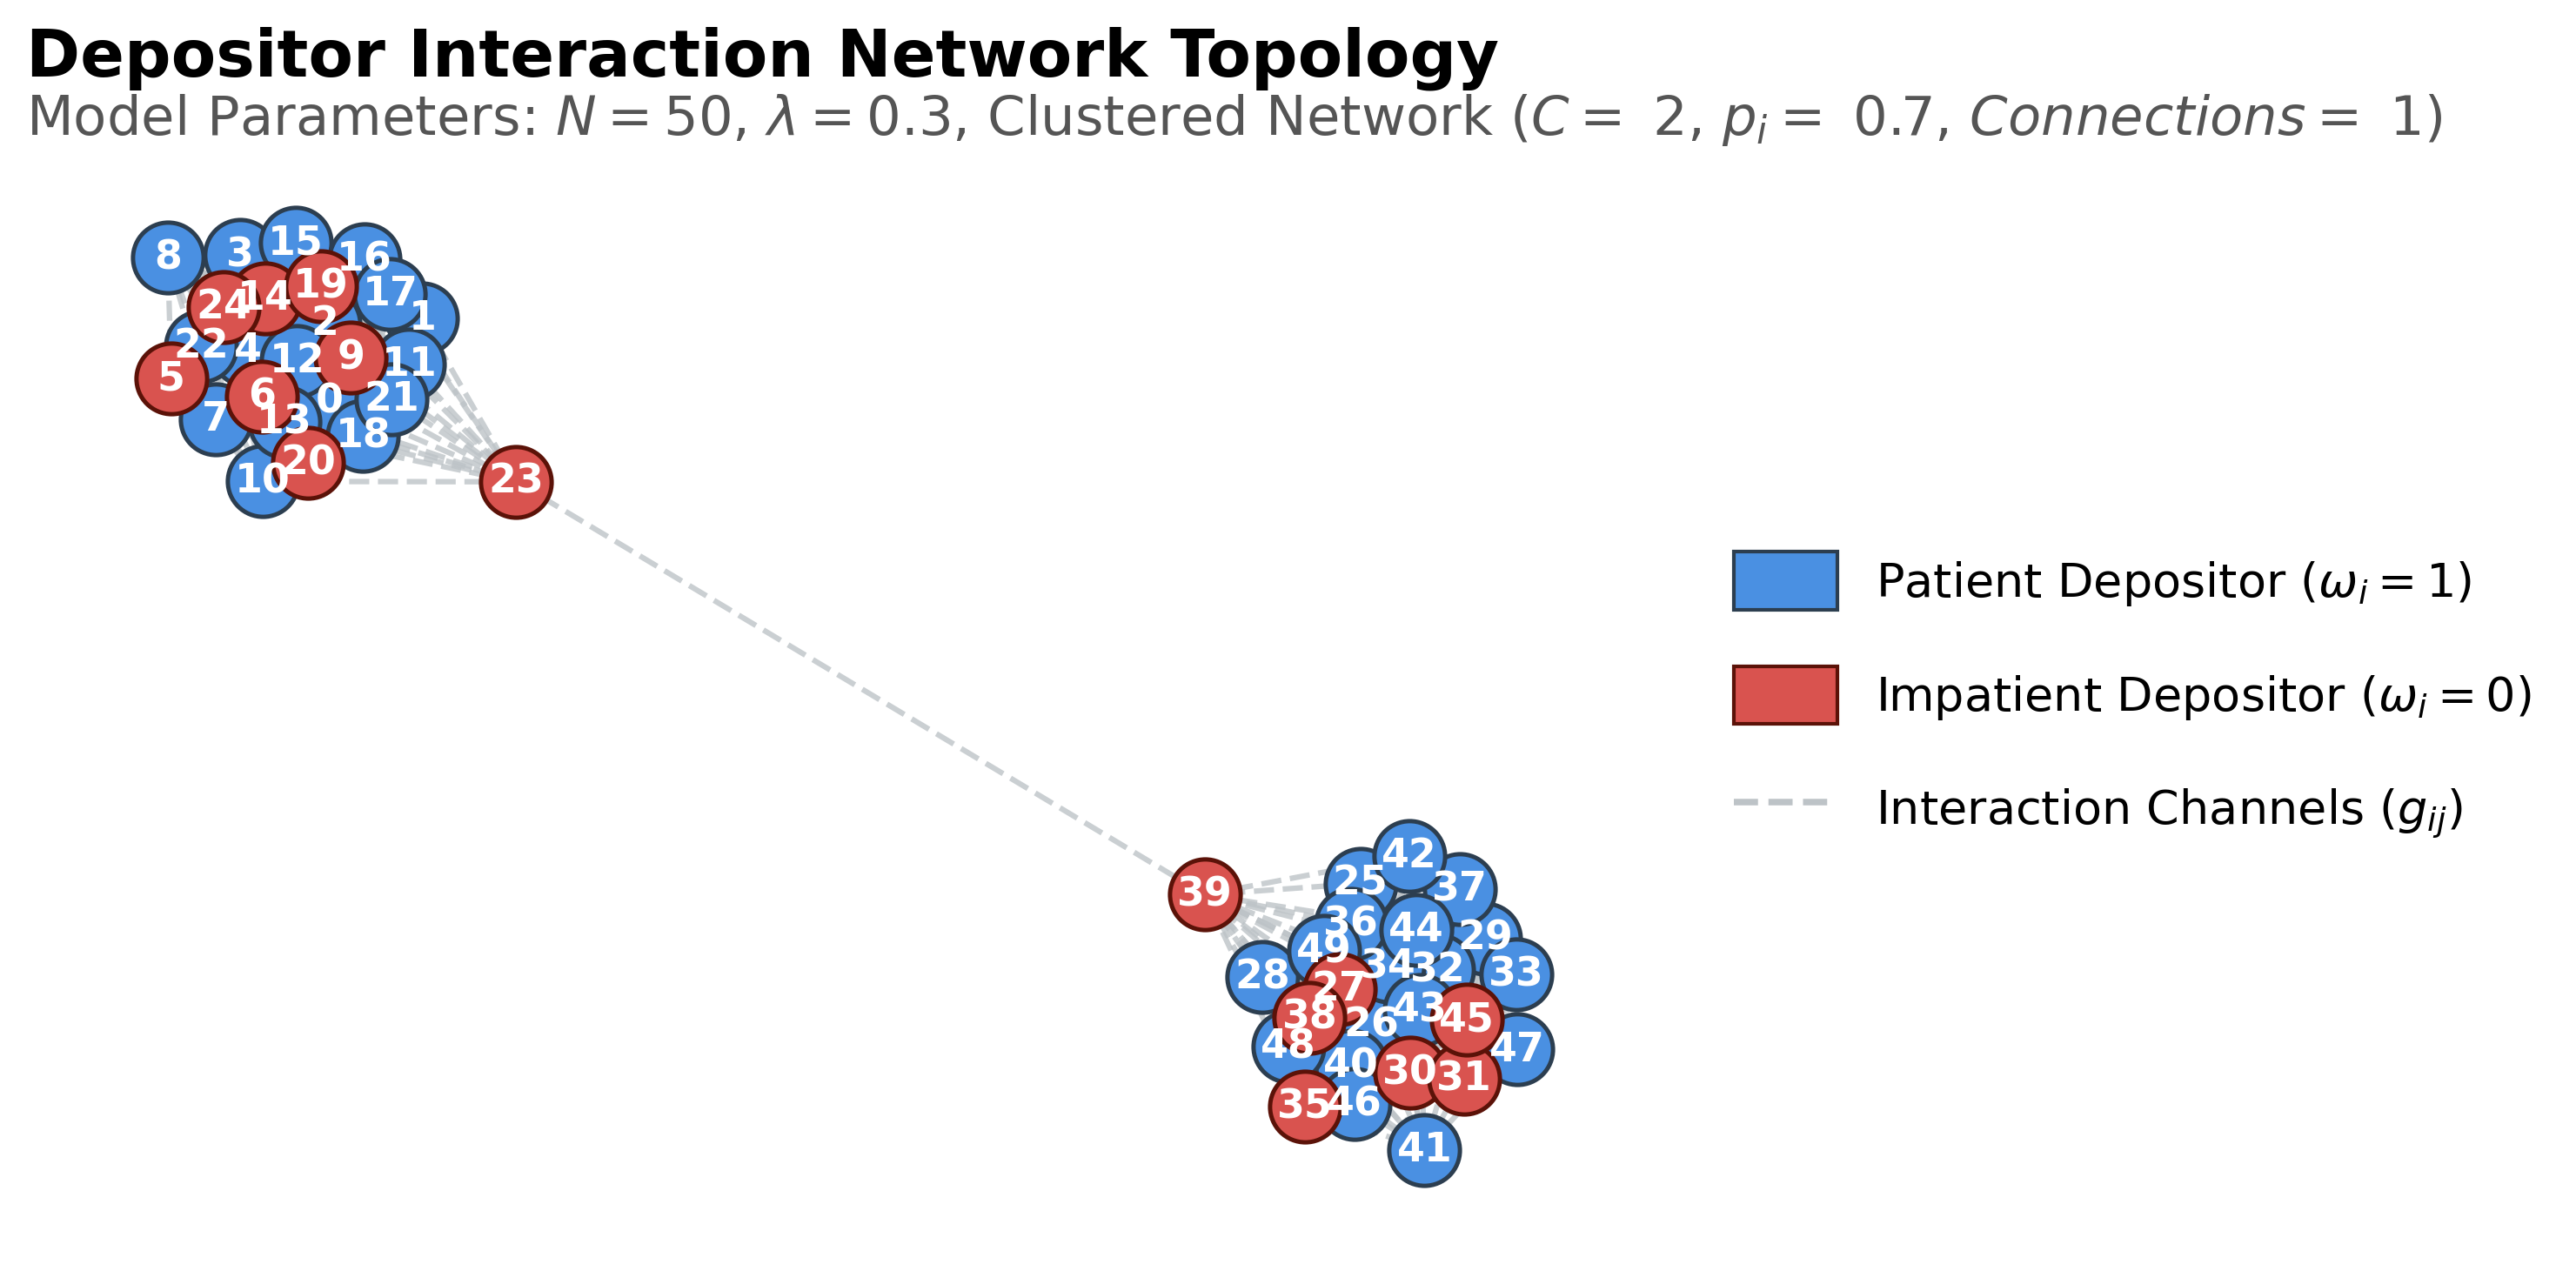

In [6]:
SIMU.network.graph()

In [22]:
# import pandas as pd

# p_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
# N_values = [10, 50, 100]
# Lambda_values = [0.3,0.4]

# results = []

# random.seed(1)
# np.random.seed(1)

# for N in N_values:
#     for Lambda in Lambda_values:
#         for p in p_values:
#             print(N, Lambda, p)
#             for simulation_id in range(1000):
        
#                 SIMU = Environment(N=N, Lambda=Lambda, network_type='random', p=p, liquidity_ratio=0, liquidation_discount=1, return_multiplier=0.5, theta=1, R=1.5, r=1.28)
#                 SIMU.simulation(printing=False)
        
#                 results.append({
#                     'N': N,
#                     'lambda': Lambda,
#                     'p': p,
#                     'simulation': simulation_id,
#                     'withdrawn_order': SIMU.withdrawn_order,
#                     'withdrawn_ammount': SIMU.withdrawn_ammount,
#                     'bank_failure': SIMU.bank_failure,
#                     'run_percentage': SIMU.run_percentage
#                 })

# df_results = pd.DataFrame(results)

10 0.3 0.1
10 0.3 0.2
10 0.3 0.3
10 0.3 0.4
10 0.3 0.5
10 0.3 0.6
10 0.3 0.7
10 0.3 0.8
10 0.3 0.9
10 0.3 1
10 0.4 0.1
10 0.4 0.2
10 0.4 0.3
10 0.4 0.4
10 0.4 0.5
10 0.4 0.6
10 0.4 0.7
10 0.4 0.8
10 0.4 0.9
10 0.4 1
50 0.3 0.1
50 0.3 0.2
50 0.3 0.3
50 0.3 0.4
50 0.3 0.5
50 0.3 0.6
50 0.3 0.7
50 0.3 0.8
50 0.3 0.9
50 0.3 1
50 0.4 0.1
50 0.4 0.2
50 0.4 0.3
50 0.4 0.4
50 0.4 0.5
50 0.4 0.6
50 0.4 0.7
50 0.4 0.8
50 0.4 0.9
50 0.4 1
100 0.3 0.1
100 0.3 0.2
100 0.3 0.3
100 0.3 0.4
100 0.3 0.5
100 0.3 0.6
100 0.3 0.7
100 0.3 0.8
100 0.3 0.9
100 0.3 1
100 0.4 0.1
100 0.4 0.2
100 0.4 0.3
100 0.4 0.4
100 0.4 0.5
100 0.4 0.6
100 0.4 0.7
100 0.4 0.8
100 0.4 0.9
100 0.4 1


In [40]:
# df_results.to_pickle('outputs/MODEL/df_results.pkl')
df_results = pd.read_pickle('outputs/MODEL/df_results.pkl')

In [41]:
DF11 = df_results[(df_results['N'] == 10) & (df_results['lambda'] == 0.3)]
DF12 = df_results[(df_results['N'] == 50) & (df_results['lambda'] == 0.3)]
DF13 = df_results[(df_results['N'] == 100) & (df_results['lambda'] == 0.3)]

table11 = (DF11.groupby('p', as_index=False)['bank_failure'].mean().rename(columns={'bank_failure': 'average_bank_failure'}))
table12 = (DF12.groupby('p', as_index=False)['bank_failure'].mean().rename(columns={'bank_failure': 'average_bank_failure'}))
table13 = (DF13.groupby('p', as_index=False)['bank_failure'].mean().rename(columns={'bank_failure': 'average_bank_failure'}))

print(table11)
print('\n',table12)
print('\n',table13)

     p  average_bank_failure
0  0.1                 0.184
1  0.2                 0.169
2  0.3                 0.392
3  0.4                 0.614
4  0.5                 0.748
5  0.6                 0.802
6  0.7                 0.772
7  0.8                 0.718
8  0.9                 0.397
9  1.0                 0.000

      p  average_bank_failure
0  0.1                 0.983
1  0.2                 1.000
2  0.3                 1.000
3  0.4                 1.000
4  0.5                 1.000
5  0.6                 0.998
6  0.7                 0.984
7  0.8                 0.896
8  0.9                 0.305
9  1.0                 0.000

      p  average_bank_failure
0  0.1                 1.000
1  0.2                 1.000
2  0.3                 1.000
3  0.4                 1.000
4  0.5                 1.000
5  0.6                 1.000
6  0.7                 0.975
7  0.8                 0.778
8  0.9                 0.044
9  1.0                 0.000


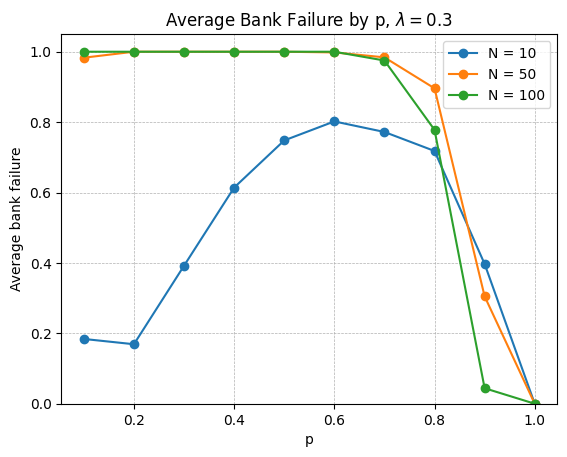

In [44]:
plt.plot(table11['p'],table11['average_bank_failure'], '-o', label  = 'N = 10')
plt.plot(table12['p'],table12['average_bank_failure'], '-o', label  = 'N = 50')
plt.plot(table13['p'],table13['average_bank_failure'], '-o', label  = 'N = 100')
plt.xlabel('p')
plt.ylabel('Average bank failure')
plt.title(r'Average Bank Failure by p, $\lambda = 0.3$')
plt.grid(ls = 'dashed', lw = 0.5)
plt.ylim(0,1.05)
plt.legend()
plt.show()

In [32]:
pivot11 = pd.pivot_table(DF11,index='p', columns='bank_failure', values='run_percentage', aggfunc='mean')
pivot12 = pd.pivot_table(DF12,index='p', columns='bank_failure', values='run_percentage', aggfunc='mean')
pivot13 = pd.pivot_table(DF13,index='p', columns='bank_failure', values='run_percentage', aggfunc='mean')

print(pivot11)
print('\n',pivot12)
print('\n',pivot13)

bank_failure     False     True 
p                               
0.1           0.541912  0.841848
0.2           0.483875  0.871006
0.3           0.455921  0.920153
0.4           0.401813  0.960261
0.5           0.361111  0.981283
0.6           0.321717  0.995511
0.7           0.309211  0.999611
0.8           0.302128  0.999861
0.9           0.300332  1.000000
1.0           0.300000       NaN

 bank_failure     False    True 
p                              
0.1           0.451765  0.92118
0.2                NaN  0.99382
0.3                NaN  0.99962
0.4                NaN  0.99998
0.5                NaN  1.00000
0.6           0.300000  1.00000
0.7           0.302500  1.00000
0.8           0.300769  1.00000
0.9           0.300259  1.00000
1.0           0.300000      NaN

 bank_failure     False    True 
p                              
0.1                NaN  0.99124
0.2                NaN  0.99993
0.3                NaN  1.00000
0.4                NaN  1.00000
0.5                NaN  

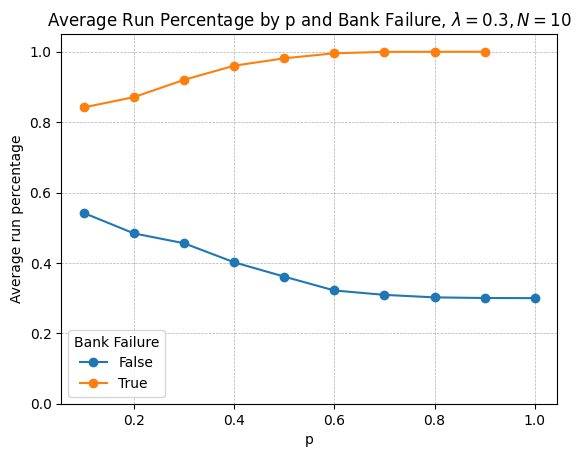

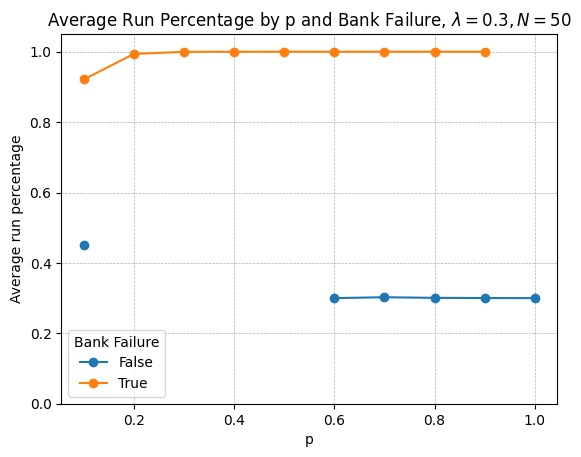

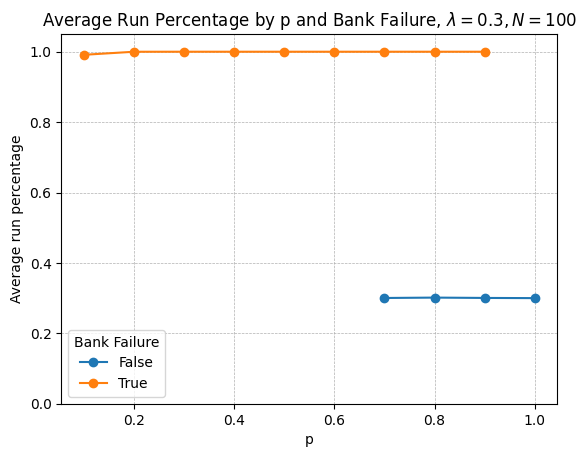

In [45]:
pivot11.plot(marker='o')
plt.xlabel('p')
plt.ylabel('Average run percentage')
plt.title(r'Average Run Percentage by p and Bank Failure, $\lambda = 0.3, N = 10$')
plt.legend(title='Bank Failure')
plt.grid(ls = 'dashed', lw = 0.5)
plt.ylim(0,1.05)

pivot12.plot(marker='o')
plt.xlabel('p')
plt.ylabel('Average run percentage')
plt.title(r'Average Run Percentage by p and Bank Failure, $\lambda = 0.3, N = 50$')
plt.legend(title='Bank Failure')
plt.grid(ls = 'dashed', lw = 0.5)
plt.ylim(0,1.05)

pivot13.plot(marker='o')
plt.xlabel('p')
plt.ylabel('Average run percentage')
plt.title(r'Average Run Percentage by p and Bank Failure, $\lambda = 0.3, N = 100$')
plt.legend(title='Bank Failure')
plt.grid(ls = 'dashed', lw = 0.5)
plt.ylim(0,1.05)
plt.show()

In [35]:
DF21 = df_results[(df_results['N'] == 10) & (df_results['lambda'] == 0.4)]
DF22 = df_results[(df_results['N'] == 50) & (df_results['lambda'] == 0.4)]
DF23 = df_results[(df_results['N'] == 100) & (df_results['lambda'] == 0.4)]

table21 = (DF21.groupby('p', as_index=False)['bank_failure'].mean().rename(columns={'bank_failure': 'average_bank_failure'}))
table22 = (DF22.groupby('p', as_index=False)['bank_failure'].mean().rename(columns={'bank_failure': 'average_bank_failure'}))
table23 = (DF23.groupby('p', as_index=False)['bank_failure'].mean().rename(columns={'bank_failure': 'average_bank_failure'}))

print(table21)
print('\n',table22)
print('\n',table23)

     p  average_bank_failure
0  0.1                 0.351
1  0.2                 0.443
2  0.3                 0.684
3  0.4                 0.870
4  0.5                 0.955
5  0.6                 0.985
6  0.7                 0.998
7  0.8                 0.998
8  0.9                 1.000
9  1.0                 1.000

      p  average_bank_failure
0  0.1                 0.999
1  0.2                 1.000
2  0.3                 1.000
3  0.4                 1.000
4  0.5                 1.000
5  0.6                 1.000
6  0.7                 1.000
7  0.8                 1.000
8  0.9                 1.000
9  1.0                 1.000

      p  average_bank_failure
0  0.1                   1.0
1  0.2                   1.0
2  0.3                   1.0
3  0.4                   1.0
4  0.5                   1.0
5  0.6                   1.0
6  0.7                   1.0
7  0.8                   1.0
8  0.9                   1.0
9  1.0                   1.0


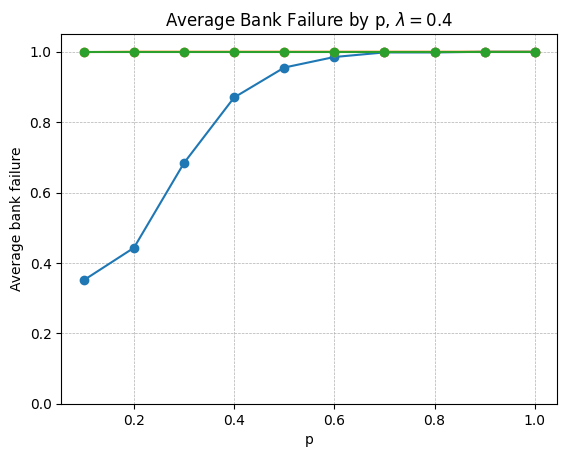

In [48]:
plt.plot(table21['p'],table21['average_bank_failure'], '-o', label = '$N = 10$')
plt.plot(table22['p'],table22['average_bank_failure'], '-o', label = '$N = 50$')
plt.plot(table23['p'],table23['average_bank_failure'], '-o', label = '$N = 100$')
plt.xlabel('p')
plt.ylabel('Average bank failure')
plt.title(r'Average Bank Failure by p, $\lambda = 0.4$')
plt.grid(ls = 'dashed', lw = 0.5)
plt.ylim(0,1.05)
plt.show()

In [37]:
pivot21 = pd.pivot_table(DF21,index='p', columns='bank_failure', values='run_percentage', aggfunc='mean')
pivot22 = pd.pivot_table(DF22,index='p', columns='bank_failure', values='run_percentage', aggfunc='mean')
pivot23 = pd.pivot_table(DF23,index='p', columns='bank_failure', values='run_percentage', aggfunc='mean')

print(pivot21)
print('\n',pivot22)
print('\n',pivot23)

bank_failure     False     True 
p                               
0.1           0.603544  0.859259
0.2           0.573070  0.889391
0.3           0.560127  0.931287
0.4           0.528462  0.966782
0.5           0.475556  0.984817
0.6           0.426667  0.995939
0.7           0.400000  0.999098
0.8           0.400000  1.000000
0.9                NaN  1.000000
1.0                NaN  1.000000

 bank_failure  False     True 
p                            
0.1            0.56  0.939119
0.2             NaN  0.996100
0.3             NaN  0.999820
0.4             NaN  1.000000
0.5             NaN  1.000000
0.6             NaN  1.000000
0.7             NaN  1.000000
0.8             NaN  1.000000
0.9             NaN  1.000000
1.0             NaN  1.000000

 bank_failure     True
p                    
0.1           0.99429
0.2           0.99997
0.3           1.00000
0.4           1.00000
0.5           1.00000
0.6           1.00000
0.7           1.00000
0.8           1.00000
0.9           1.0000

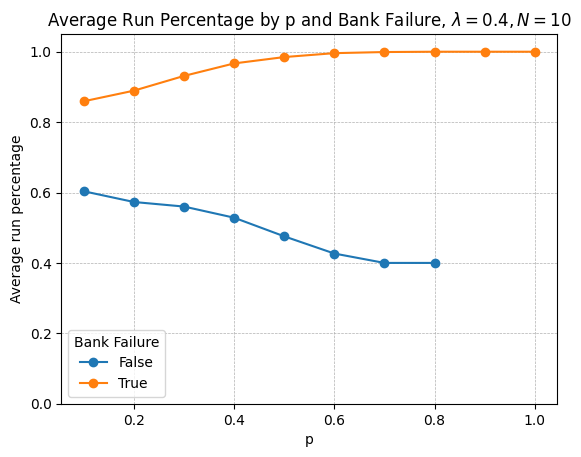

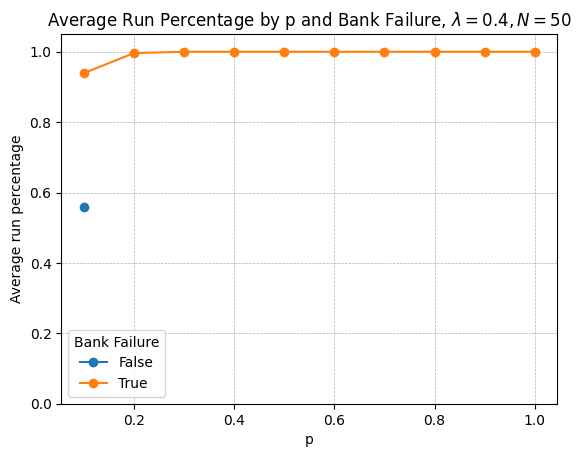

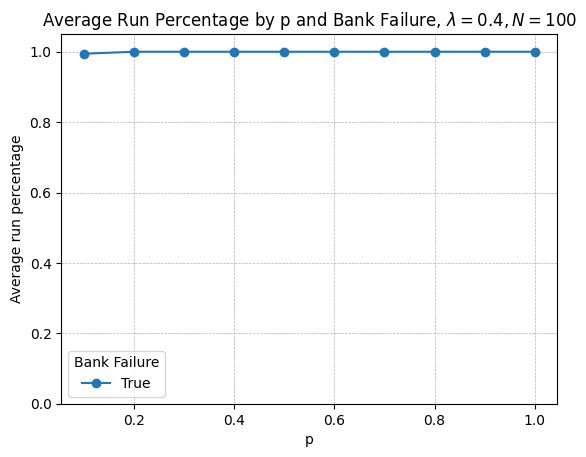

In [49]:
pivot21.plot(marker='o')
plt.xlabel('p')
plt.ylabel('Average run percentage')
plt.title(r'Average Run Percentage by p and Bank Failure, $\lambda = 0.4, N = 10$')
plt.legend(title='Bank Failure')
plt.grid(ls = 'dashed', lw = 0.5)
plt.ylim(0,1.05)

pivot22.plot(marker='o')
plt.xlabel('p')
plt.ylabel('Average run percentage')
plt.title(r'Average Run Percentage by p and Bank Failure, $\lambda = 0.4, N = 50$')
plt.legend(title='Bank Failure')
plt.grid(ls = 'dashed', lw = 0.5)
plt.ylim(0,1.05)

pivot23.plot(marker='o')
plt.xlabel('p')
plt.ylabel('Average run percentage')
plt.title(r'Average Run Percentage by p and Bank Failure, $\lambda = 0.4, N = 100$')
plt.legend(title='Bank Failure')
plt.grid(ls = 'dashed', lw = 0.5)
plt.ylim(0,1.05)
plt.show()